<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Ejercicios/Soluciones/01_Taller_Sentimiento_RL_NB_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Taller práctico: análisis de sentimiento con regresión logística y Naive Bayes (solución)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Solución de referencia del taller [`01_Taller_Sentimiento_RL_NB.ipynb`](../01_Taller_Sentimiento_RL_NB.ipynb).

Hay muchas soluciones válidas: esta es una de ellas. Compara tus resultados y, sobre todo, tus conclusiones.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Ejercicio 1. Exploración y división de los datos</span>](#ejercicio-1)
- [<span style="color: #005C99;">Ejercicio 2. Preprocesamiento con manejo de negaciones</span>](#ejercicio-2)
- [<span style="color: #005C99;">Ejercicio 3. Regresión logística con frecuencias de palabras por clase</span>](#ejercicio-3)
- [<span style="color: #005C99;">Ejercicio 4. Naive Bayes y la selección del suavizado</span>](#ejercicio-4)
- [<span style="color: #005C99;">Ejercicio 5. Comparación de modelos y análisis de errores</span>](#ejercicio-5)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn scipy nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import string
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import movie_reviews

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

SEED = 42
np.random.seed(SEED)

for recurso in ["movie_reviews", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Exploración y división de los datos</h2>

**Objetivo:** cargar el corpus, entender su estructura y crear una división entrenamiento/prueba sin fugas de información.

`movie_reviews` contiene 2 000 reseñas de películas en inglés, 1 000 positivas (`pos`) y 1 000 negativas (`neg`). Cada reseña es un archivo; se accede con `movie_reviews.fileids(categoria)` y `movie_reviews.raw(fileid)`.

1. Construye un `DataFrame` llamado `df` con las columnas `texto` y `etiqueta` (1 = positiva, 0 = negativa).
2. Agrega una columna `n_palabras` y reporta la media, la mediana y el máximo de palabras por reseña, por clase. ¿Hay diferencia de longitud entre clases?
3. Divide en entrenamiento (80 %) y prueba (20 %) de forma **estratificada** con `random_state=SEED`. Llama a los resultados `X_train_txt`, `X_test_txt`, `y_train`, `y_test` (las etiquetas como arreglos de NumPy).
4. Compara la longitud típica de estas reseñas con la de los tweets del cuaderno 03 (≈ 10–20 palabras). ¿Qué implicaciones crees que tiene para la representación?

In [3]:
filas = [(movie_reviews.raw(fid), 1 if cat == "pos" else 0)
         for cat in ["pos", "neg"] for fid in movie_reviews.fileids(cat)]
df = pd.DataFrame(filas, columns=["texto", "etiqueta"])
df["n_palabras"] = df.texto.str.split().str.len()

print(df.etiqueta.value_counts())
df.groupby("etiqueta").n_palabras.agg(["mean", "median", "max"]).round(1)

etiqueta
1    1000
0    1000
Name: count, dtype: int64


,mean,median,max
etiqueta,,,
0,705.6,668.5,2181
1,787.1,731.5,2678


In [4]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df.texto.tolist(), df.etiqueta.values, test_size=0.2, stratify=df.etiqueta, random_state=SEED
)
print(f"Entrenamiento: {len(X_train_txt)} | Prueba: {len(X_test_txt)} | Positivos en train: {y_train.mean():.2f}")

Entrenamiento: 1600 | Prueba: 400 | Positivos en train: 0.50


**Respuestas:**

- El corpus está perfectamente balanceado. Las reseñas positivas son, en promedio, un poco más largas que las negativas, pero la diferencia es pequeña frente a la variación dentro de cada clase, así que la longitud por sí sola no es una buena característica.
- Las reseñas tienen del orden de **700 palabras**, unas 40 veces más que un tweet. Cada documento contiene muchas más palabras distintas, y cualquier característica que **sume** algo sobre las palabras (como las frecuencias del cuaderno 03) crecerá con la longitud del texto más que con su sentimiento. Además, una reseña larga suele mezclar aspectos positivos y negativos (*"la actuación es buena, pero el guion es terrible"*), lo que hace la tarea más difícil que con tweets cortos.

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. Preprocesamiento con manejo de negaciones</h2>

**Objetivo:** implementar el marcado de negaciones, una técnica clásica para que los modelos de bolsa de palabras capten frases como *not good*.

Vimos que los modelos de bolsa de palabras no entienden *"not good"*. Una solución simple (Das & Chen, 2001; Pang et al., 2002) es **añadir el prefijo `NOT_` a cada palabra que sigue a una negación, hasta el siguiente signo de puntuación**:

```text
"i did n't like this movie , but the actors were great"
 -> ['i', 'did', "n't", 'NOT_like', 'NOT_this', 'NOT_movie', ',', 'but', 'the', 'actors', 'were', 'great']
```

1. Implementa `tokenizar(texto)` que pase a minúsculas y tokenice con `nltk.word_tokenize`.
2. Implementa `marcar_negaciones(tokens)` usando el conjunto `NEGACIONES` y la puntuación `PUNTUACION` dados.
3. Implementa `preprocesar(texto, negaciones=True)` que tokenice, aplique (opcionalmente) el marcado y **elimine** los signos de puntuación.
4. Pruébala con las frases de ejemplo.

In [5]:
NEGACIONES = {"not", "no", "never", "n't", "nothing", "nobody", "nor", "neither", "without", "cannot"}
PUNTUACION = set(string.punctuation)


def tokenizar(texto):
    return nltk.word_tokenize(texto.lower())


def marcar_negaciones(tokens):
    resultado, negando = [], False
    for t in tokens:
        if t in PUNTUACION:
            negando = False
            resultado.append(t)
        elif t in NEGACIONES:
            negando = True
            resultado.append(t)
        else:
            resultado.append("NOT_" + t if negando else t)
    return resultado


def preprocesar(texto, negaciones=True):
    tokens = tokenizar(texto)
    if negaciones:
        tokens = marcar_negaciones(tokens)
    return [t for t in tokens if t not in PUNTUACION]


for frase in ["I didn't like this movie, but the actors were great.",
              "Not a bad film at all. Never boring!"]:
    print(preprocesar(frase))

['i', 'did', "n't", 'NOT_like', 'NOT_this', 'NOT_movie', 'but', 'the', 'actors', 'were', 'great']
['not', 'NOT_a', 'NOT_bad', 'NOT_film', 'NOT_at', 'NOT_all', 'never', 'NOT_boring']


Observa que `word_tokenize` separa *didn't* en `did` + `n't`, por eso incluimos `n't` en las negaciones. En *"Not a bad film"* el marcado produce `NOT_bad`, una característica distinta de `bad`, que el modelo puede aprender como positiva.

In [6]:
# Tokenizamos una sola vez: lo reutilizaremos en los siguientes ejercicios
tok_train = [preprocesar(t) for t in X_train_txt]
tok_test = [preprocesar(t) for t in X_test_txt]
tok_train_sin = [preprocesar(t, negaciones=False) for t in X_train_txt]
tok_test_sin = [preprocesar(t, negaciones=False) for t in X_test_txt]

n_marcados = sum(t.startswith("NOT_") for doc in tok_train for t in doc)
print(f"Tokens marcados con NOT_ en entrenamiento: {n_marcados:,}")

Tokens marcados con NOT_ en entrenamiento: 84,436


---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Regresión logística con frecuencias de palabras por clase</h2>

**Objetivo:** aplicar a las reseñas la representación de dos características del cuaderno 03 (suma de frecuencias positivas y negativas), entrenar la regresión logística desde cero y analizar las limitaciones de esta representación con textos largos.

En el cuaderno 03 representamos cada tweet con tres números: el sesgo y las sumas de las frecuencias de sus palabras en la clase positiva y en la negativa,

$$\mathbf{x} = \left[\,1,\; \sum_{j} \text{freqs}(w_j, 1),\; \sum_{j} \text{freqs}(w_j, 0)\,\right],$$

donde $w_1, \dots, w_m$ son las palabras únicas del texto. Ahora aplicaremos la misma idea a las reseñas.

1. Implementa `construir_frecuencias(tokens_por_doc, y)`, que devuelva un `Counter` con las apariciones de cada par `(palabra, clase)`, y calcúlalo **solo** con `tok_train`.
2. Implementa `extraer_caracteristicas(tokens, freqs)` y construye las matrices `F_train` y `F_test`. Como en el cuaderno 03, aplica $\log(1 + x)$, estandariza con la media y la desviación del conjunto de **entrenamiento** y agrega la columna de sesgo. Llama a las matrices finales `X_train` y `X_test`.
3. Calcula la correlación entre las dos características y grafica las reseñas de entrenamiento en el plano (característica positiva, característica negativa). Compara con el gráfico de los tweets del cuaderno 03. ¿Por qué las dos características están tan correlacionadas? Pista: calcula también su correlación con el número de palabras únicas de la reseña.
4. Implementa `descenso_gradiente(X, y, alpha, n_iter)` como en el cuaderno 03, entrena con `alpha=0.5` y `n_iter=1000` y grafica el costo.
5. Verifica tu implementación con `LogisticRegression(C=np.inf)` de scikit-learn (sin regularización): compara los parámetros y las predicciones.
6. Reporta la exactitud en entrenamiento y en prueba y compárala con la de los tweets del cuaderno 03. ¿A qué atribuyes la diferencia entre la exactitud en entrenamiento y la de prueba? Pista: ¿las frecuencias con las que se representa una reseña de entrenamiento incluyen las palabras de esa misma reseña?

In [7]:
def construir_frecuencias(tokens_por_doc, y):
    freqs = Counter()
    for tokens, etiqueta in zip(tokens_por_doc, y):
        for palabra in tokens:
            freqs[(palabra, int(etiqueta))] += 1
    return freqs


freqs = construir_frecuencias(tok_train, y_train)
print(f"Pares (palabra, clase) distintos: {len(freqs):,}")

palabras_ejemplo = ["great", "excellent", "bad", "worst", "boring", "NOT_funny", "the", "movie"]
pd.DataFrame(
    [(p, freqs[(p, 1)], freqs[(p, 0)]) for p in palabras_ejemplo],
    columns=["palabra", "frec. positiva", "frec. negativa"],
)

Pares (palabra, clase) distintos: 70,561


,palabra,frec. positiva,frec. negativa
0,great,548,265
1,excellent,122,25
2,bad,213,682
3,worst,36,198
4,boring,32,154
5,NOT_funny,24,107
6,the,30828,25547
7,movie,1809,2257


In [8]:
def extraer_caracteristicas(tokens, freqs):
    unicas = set(tokens)
    pos = sum(freqs[(w, 1)] for w in unicas)
    neg = sum(freqs[(w, 0)] for w in unicas)
    return np.array([pos, neg], dtype=float)


def agregar_sesgo(F):
    return np.hstack([np.ones((len(F), 1)), F])


F_train = np.array([extraer_caracteristicas(t, freqs) for t in tok_train])
F_test = np.array([extraer_caracteristicas(t, freqs) for t in tok_test])

F_train_log, F_test_log = np.log1p(F_train), np.log1p(F_test)
media, desv = F_train_log.mean(axis=0), F_train_log.std(axis=0)
X_train = agregar_sesgo((F_train_log - media) / desv)
X_test = agregar_sesgo((F_test_log - media) / desv)
print("Forma de X_train:", X_train.shape)

Forma de X_train: (1600, 3)


Correlación entre las dos características: 0.995
Correlación con el número de palabras únicas: positiva 0.835 | negativa 0.823


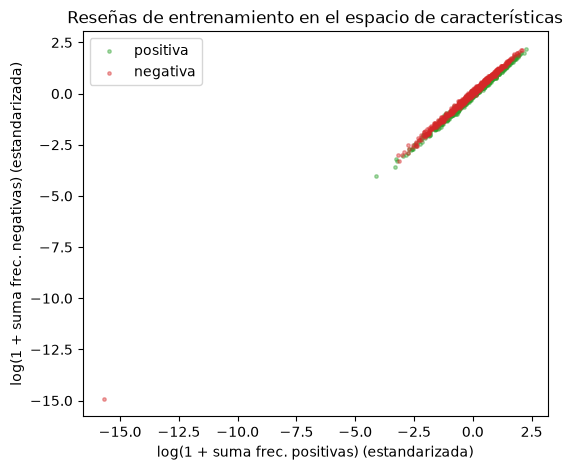

In [9]:
n_unicas = np.array([len(set(t)) for t in tok_train])
print(f"Correlación entre las dos características: {np.corrcoef(X_train[:, 1], X_train[:, 2])[0, 1]:.3f}")
print(f"Correlación con el número de palabras únicas: positiva {np.corrcoef(X_train[:, 1], n_unicas)[0, 1]:.3f}"
      f" | negativa {np.corrcoef(X_train[:, 2], n_unicas)[0, 1]:.3f}")

plt.figure(figsize=(6, 5))
for clase, color, nombre in [(1, "tab:green", "positiva"), (0, "tab:red", "negativa")]:
    m = y_train == clase
    plt.scatter(X_train[m, 1], X_train[m, 2], s=6, alpha=0.4, c=color, label=nombre)
plt.xlabel("log(1 + suma frec. positivas) (estandarizada)")
plt.ylabel("log(1 + suma frec. negativas) (estandarizada)")
plt.title("Reseñas de entrenamiento en el espacio de características")
plt.legend()
plt.show()

**Interpretación:** a diferencia de los tweets, las dos características están casi perfectamente correlacionadas y los puntos forman una línea diagonal. Una reseña tiene cientos de palabras únicas, y la mayoría (*the*, *film*, *story*, *character*...) aparece muchas veces en las dos clases. Cada palabra suma a la vez a la característica positiva y a la negativa, así que ambas crecen con la **longitud** de la reseña más que con su sentimiento. La información útil queda en la pequeña diferencia entre las dos, es decir, en la distancia perpendicular a la diagonal, donde las clases se superponen mucho.

Parámetros aprendidos (sesgo, peso_pos, peso_neg): [-2.000e-03  5.725e+00 -5.631e+00]


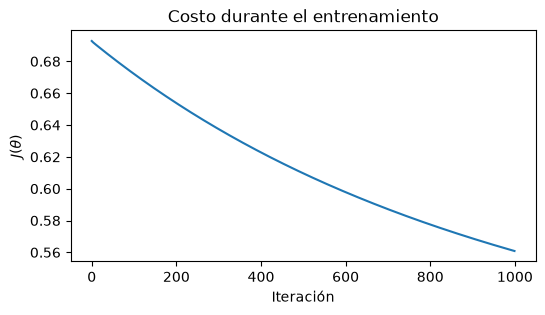

In [10]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def costo(X, y, theta, eps=1e-12):
    h = sigmoide(X @ theta)
    return -np.mean(y * np.log(h + eps) + (1 - y) * np.log(1 - h + eps))


def descenso_gradiente(X, y, alpha=0.5, n_iter=1000):
    theta = np.zeros(X.shape[1])
    historial = []
    for _ in range(n_iter):
        gradiente = X.T @ (sigmoide(X @ theta) - y) / len(y)
        theta -= alpha * gradiente
        historial.append(costo(X, y, theta))
    return theta, historial


theta, historial = descenso_gradiente(X_train, y_train, alpha=0.5, n_iter=1000)
print("Parámetros aprendidos (sesgo, peso_pos, peso_neg):", np.round(theta, 3))

plt.figure(figsize=(6, 3))
plt.plot(historial)
plt.xlabel("Iteración")
plt.ylabel(r"$J(\theta)$")
plt.title("Costo durante el entrenamiento")
plt.show()

In [11]:
def predecir(X, theta):
    return (sigmoide(X @ theta) >= 0.5).astype(int)


# X_train ya incluye la columna de sesgo, así que no ajustamos un intercepto aparte
sk = LogisticRegression(C=np.inf, fit_intercept=False, max_iter=5000).fit(X_train, y_train)
print("Parámetros scikit-learn:", np.round(sk.coef_[0], 3))
print(f"Predicciones idénticas en prueba: {np.mean(sk.predict(X_test) == predecir(X_test, theta)):.2%}")

print(f"\nExactitud en entrenamiento: {accuracy_score(y_train, predecir(X_train, theta)):.4f}")
print(f"Exactitud en prueba:        {accuracy_score(y_test, predecir(X_test, theta)):.4f}")

Parámetros scikit-learn: [ 1.1000e-02  2.1779e+01 -2.1503e+01]
Predicciones idénticas en prueba: 98.75%
Exactitud en entrenamiento: 0.8025
Exactitud en prueba:        0.7600


**Interpretación:**

- Los pesos tienen los signos esperados (positivo para la característica positiva y negativo para la negativa) y son casi iguales en valor absoluto: el modelo usa en la práctica la **diferencia** entre las dos características. scikit-learn llega a pesos unas cuatro veces mayores y, aun así, las predicciones coinciden en casi todas las reseñas. Como las características están tan correlacionadas, el costo es casi plano en la dirección en la que los dos pesos crecen juntos con signos opuestos; el descenso del gradiente avanza muy despacio en esa dirección y 1 000 iteraciones no bastan para llegar al mínimo, aunque la frontera de decisión ya casi no cambia.
- La exactitud cae de casi 100 % con los tweets a alrededor de 76 % con las reseñas. Los tweets eran cortos y muchos contenían un emoticón que casi decidía la clase. En una reseña larga, unas pocas palabras de opinión se diluyen entre cientos de palabras neutras que suman a las dos clases.
- La exactitud en entrenamiento es varios puntos más alta que en prueba. No es sobreajuste de los parámetros (solo hay tres), sino una **fuga de información** en las características: `freqs` se construyó con las reseñas de entrenamiento, así que la representación de cada reseña de entrenamiento incluye sus propias palabras contadas con su propia etiqueta. Las palabras raras (nombres de actores, de personajes, de películas) aparecen casi solo en esa reseña y empujan su característica hacia la clase correcta. Las reseñas de prueba no tienen esa ventaja.
- Representar un texto con solo dos sumas descarta casi toda la información. En el ejercicio 4 veremos que Naive Bayes, que combina la evidencia de cada palabra por separado mediante razones de verosimilitud, aprovecha mucho mejor el vocabulario.

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. Naive Bayes y la selección del suavizado</h2>

**Objetivo:** implementar Naive Bayes multinomial con suavizado aditivo y elegir $\alpha$ con validación cruzada, sin tocar el conjunto de prueba.

1. Implementa `entrenar_nb(tokens_por_doc, y, alpha)` y `predecir_nb(modelo, tokens_por_doc)` (puedes reutilizar la lógica del cuaderno 04, pero esta vez $\alpha$ es un parámetro).
2. Verifica tu implementación: con `alpha=1` debe dar las mismas predicciones que `make_pipeline(CountVectorizer(...), MultinomialNB(alpha=1))` usando el mismo tokenizado.
3. Usa **validación cruzada estratificada de 5 particiones** (sobre el conjunto de entrenamiento) para evaluar $\alpha \in \{0.01, 0.05, 0.1, 0.5, 1, 2, 5\}$. Puedes usar `cross_val_score` con el pipeline de scikit-learn.
4. Grafica la exactitud media (con su desviación estándar) contra $\alpha$ en escala logarítmica.
5. Elige el mejor $\alpha$, reentrena con todo el conjunto de entrenamiento y evalúa **una sola vez** en prueba.
6. ¿Qué ocurre con valores de $\alpha$ muy pequeños y muy grandes? Explica por qué.

In [12]:
def entrenar_nb(tokens_por_doc, y, alpha=1.0):
    conteos = {0: Counter(), 1: Counter()}
    for tokens, etiqueta in zip(tokens_por_doc, y):
        conteos[int(etiqueta)].update(tokens)
    vocab = set(conteos[0]) | set(conteos[1])
    n = {c: sum(conteos[c].values()) for c in (0, 1)}
    V = len(vocab)
    loglik = {w: np.log((conteos[1][w] + alpha) / (n[1] + alpha * V))
                 - np.log((conteos[0][w] + alpha) / (n[0] + alpha * V)) for w in vocab}
    logprior = np.log(np.mean(y)) - np.log(1 - np.mean(y))
    return logprior, loglik


def predecir_nb(modelo, tokens_por_doc):
    logprior, loglik = modelo
    return np.array([int(logprior + sum(loglik.get(w, 0.0) for w in doc) > 0) for doc in tokens_por_doc])


pred_propia = predecir_nb(entrenar_nb(tok_train, y_train, alpha=1.0), tok_test)

identidad = lambda x: x
nb_sk = make_pipeline(CountVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None),
                      MultinomialNB(alpha=1.0)).fit(tok_train, y_train)
print(f"Exactitud propia: {accuracy_score(y_test, pred_propia):.4f}")
print(f"Coincidencia con MultinomialNB: {np.mean(nb_sk.predict(tok_test) == pred_propia):.2%}")

Exactitud propia: 0.8175
Coincidencia con MultinomialNB: 100.00%


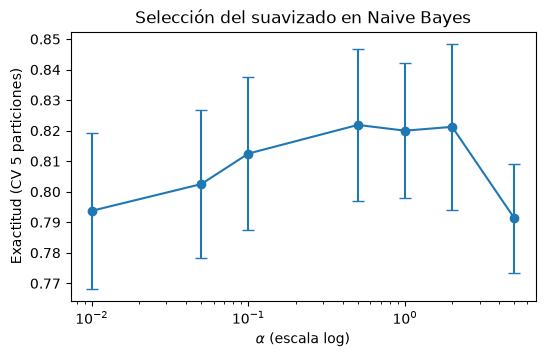

Mejor alpha según validación cruzada: 0.5


In [13]:
alphas = [0.01, 0.05, 0.1, 0.5, 1, 2, 5]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
medias, desvs = [], []
for a in alphas:
    pipe = make_pipeline(CountVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None),
                         MultinomialNB(alpha=a))
    scores = cross_val_score(pipe, tok_train, y_train, cv=cv, scoring="accuracy")
    medias.append(scores.mean())
    desvs.append(scores.std())

plt.figure(figsize=(6, 3.5))
plt.errorbar(alphas, medias, yerr=desvs, marker="o", capsize=4)
plt.xscale("log")
plt.xlabel(r"$\alpha$ (escala log)")
plt.ylabel("Exactitud (CV 5 particiones)")
plt.title("Selección del suavizado en Naive Bayes")
plt.show()

mejor_alpha = alphas[int(np.argmax(medias))]
print(f"Mejor alpha según validación cruzada: {mejor_alpha}")

In [14]:
pred_final = predecir_nb(entrenar_nb(tok_train, y_train, alpha=mejor_alpha), tok_test)
print(f"Exactitud en prueba con alpha={mejor_alpha}: {accuracy_score(y_test, pred_final):.4f}")

Exactitud en prueba con alpha=0.5: 0.8125


**Interpretación:**

- Con $\alpha$ **muy pequeño**, una palabra vista solo en una clase recibe una razón de verosimilitud enorme: el modelo confía demasiado en palabras raras (que pueden ser nombres de actores o películas) y **sobreajusta**.
- Con $\alpha$ **muy grande**, todas las probabilidades se acercan a la distribución uniforme $1/|V|$, las razones $\lambda(w)$ se aplastan hacia cero y el modelo pierde información: **subajusta**.
- El valor óptimo equilibra ambos efectos. Lo elegimos con validación cruzada **solo sobre entrenamiento**; el conjunto de prueba se usa una única vez al final para no sesgar la estimación del desempeño.

---

<a id="ejercicio-5"></a>
<h2 style="color: #007ACC;">Ejercicio 5. Comparación de modelos y análisis de errores</h2>

**Objetivo:** comparar de forma justa los modelos y variantes de preprocesamiento, e interpretar qué aprendieron y en qué se equivocan.

1. Evalúa en prueba (F1) las cuatro combinaciones: {Naive Bayes, Regresión logística} × {con marcado de negaciones, sin marcado}. Para la regresión logística usa las características de frecuencias del ejercicio 3 (recalculando `freqs` con cada preprocesamiento); para Naive Bayes usa el `mejor_alpha` del ejercicio 4. Presenta los resultados en una tabla.
2. Con el modelo Naive Bayes con marcado de negaciones, muestra las 15 palabras con mayor razón de verosimilitud $\lambda(w)$ y las 15 con menor, primero con todo el vocabulario y luego solo con las palabras presentes en al menos 30 reseñas de entrenamiento. ¿Aparecen características `NOT_`? ¿Tienen sentido?
3. Con el mejor modelo, muestra los 3 errores en los que estaba más seguro (probabilidad más lejana a 0.5) con un fragmento del texto. Lee al menos uno y explica por qué crees que falló.
4. Conclusión: ¿qué modelo recomendarías y por qué? ¿Qué limitaciones comparten?

In [15]:
def caracteristicas_frecuencias(tok_tr, tok_te, y):
    """Representación del ejercicio 3: frecuencias y estandarización calculadas solo con entrenamiento."""
    f = construir_frecuencias(tok_tr, y)
    F_tr = np.log1p([extraer_caracteristicas(t, f) for t in tok_tr])
    F_te = np.log1p([extraer_caracteristicas(t, f) for t in tok_te])
    mu, sd = F_tr.mean(axis=0), F_tr.std(axis=0)
    return agregar_sesgo((F_tr - mu) / sd), agregar_sesgo((F_te - mu) / sd)


identidad = lambda x: x
resultados = []
for nombre_prep, (tr, te) in {"con negaciones": (tok_train, tok_test),
                              "sin negaciones": (tok_train_sin, tok_test_sin)}.items():
    nb = make_pipeline(CountVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None),
                       MultinomialNB(alpha=mejor_alpha)).fit(tr, y_train)
    resultados.append(("Naive Bayes", nombre_prep, f1_score(y_test, nb.predict(te))))

    Xf_tr, Xf_te = caracteristicas_frecuencias(tr, te, y_train)
    theta_f, _ = descenso_gradiente(Xf_tr, y_train, alpha=0.5, n_iter=1000)
    resultados.append(("Regresión logística (frecuencias)", nombre_prep, f1_score(y_test, predecir(Xf_te, theta_f))))

pd.DataFrame(resultados, columns=["modelo", "preprocesamiento", "F1 prueba"]).round(4)

,modelo,preprocesamiento,F1 prueba
0,Naive Bayes,con negaciones,0.8139
1,Regresión logística (frecuencias),con negaciones,0.7500
2,Naive Bayes,sin negaciones,0.8060
3,Regresión logística (frecuencias),sin negaciones,0.7532


In [16]:
logprior, loglik = entrenar_nb(tok_train, y_train, alpha=mejor_alpha)
orden_todas = sorted(loglik, key=loglik.get)
print("Sin filtrar, las más negativas:", orden_todas[:6])
print("Sin filtrar, las más positivas:", orden_todas[::-1][:6])

# Solo palabras presentes en al menos 30 reseñas, para que no dominen los nombres propios de una sola película
n_resenas = Counter(w for doc in tok_train for w in set(doc))
orden = [w for w in orden_todas if n_resenas[w] >= 30]
pd.DataFrame({
    "más negativas": orden[:15],
    "λ (-)": [round(loglik[w], 2) for w in orden[:15]],
    "más positivas": orden[::-1][:15],
    "λ (+)": [round(loglik[w], 2) for w in orden[::-1][:15]],
})

Sin filtrar, las más negativas: ['nbsp', 'jawbreaker', 'magoo', 'jakob', 'webb', 'brenner']
Sin filtrar, las más positivas: ['mulan', 'flynt', 'shrek', 'ordell', 'sweetback', 'leila']


,más negativas,λ (-),más positivas,λ (+)
0,ludicrous,-3.11,finest,2.63
1,poorly,-2.14,outstanding,2.39
2,uninteresting,-2.12,wonderfully,1.99
3,inept,-1.97,satisfying,1.84
4,ridiculous,-1.97,anger,1.71
5,NOT_script,-1.88,nomination,1.62
6,wasted,-1.85,breathtaking,1.58
7,worst,-1.80,refreshing,1.57
8,eve,-1.75,beautifully,1.57
9,waste,-1.75,titanic,1.57


In [17]:
no_feats = [w for w in orden if w.startswith("NOT_")]
print("Características NOT_ más negativas:", no_feats[:8])
print("Características NOT_ más positivas:", no_feats[-8:])

Características NOT_ más negativas: ['NOT_script', 'NOT_save', 'NOT_funny', 'NOT_interesting', 'NOT_reason', 'NOT_explained', 'NOT_fun', 'NOT_bit']
Características NOT_ más positivas: ['NOT_same', 'NOT_quite', 'NOT_live', 'NOT_world', 'NOT_best', 'NOT_everyone', 'NOT_short', 'NOT_perfect']


In [18]:
modelo = make_pipeline(CountVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None),
                       MultinomialNB(alpha=mejor_alpha)).fit(tok_train, y_train)
probs = modelo.predict_proba(tok_test)[:, 1]
errores = np.where((probs >= 0.5) != y_test)[0]
peores = errores[np.argsort(-np.abs(probs[errores] - 0.5))][:3]
for i in peores:
    real = "positiva" if y_test[i] else "negativa"
    print(f"Real: {real} | P(positiva) = {probs[i]:.3f}")
    print(" ".join(X_test_txt[i].split())[:600], "...\n")

Real: negativa | P(positiva) = 1.000
running time approximately 1hr 40mins reviewed by jack choo rating : the movie starts with a rather se7en-ish opening sequence , rather cool and sets the mood for things to come . the story propels the audience into a neo-reality ; somewhat very close to conscious reality but laced with weird tinges of blue and red . existenz is actually the name of a new virtual-reality game . supposedly , vr games are highly popular as is considered a legal-drug in this neo-reality . * * * * ( leigh ) is the ultimate game creator and introduces her ultimate game-experience in the form of existenz . players a ...
Real: positiva | P(positiva) = 0.000
" the blair witch project " was perhaps one of a kind , a unique film that played completely on its own merit , managing to scare even the most experienced horror fans out of their senses . its success made a sequel inevitable , but this is not the sequel , i suspect , anyone much wanted . after the release of " the bla

**Interpretación y conclusiones:**

- Naive Bayes supera a la regresión logística con frecuencias por unos 6 puntos de F1, una diferencia clara. El marcado de negaciones mejora Naive Bayes en menos de un punto y no cambia la regresión logística. Con un conjunto de prueba de 400 reseñas, esas diferencias pequeñas están dentro del ruido estadístico: para afirmarlas habría que usar validación cruzada repetida o una prueba estadística.
- La diferencia entre los dos modelos está en la representación. La regresión logística ve cada reseña como **dos sumas**, en las que la evidencia de *excellent* se mezcla con la de cientos de palabras neutras. Naive Bayes conserva una razón de verosimilitud **por palabra** y las combina. En el cuaderno 05 representaremos cada palabra como una característica propia; con esa representación la regresión logística también puede asignar un peso a cada palabra.
- Sin filtrar, las razones más extremas de Naive Bayes corresponden a **nombres propios** (*mulan*, *shrek*, *flynt*, *magoo*) y hasta a restos de HTML (*nbsp*). Estas palabras aparecen en las pocas reseñas de una sola película, así que el modelo memoriza qué películas recibieron buenas críticas en este corpus, una forma de sobreajuste que no se generaliza a otras películas. Si nos quedamos con las palabras presentes en al menos 30 reseñas, aparece vocabulario de opinión con sentido: *ludicrous*, *poorly*, *inept*, *wasted* frente a *finest*, *outstanding*, *wonderfully*, *breathtaking*. Aun así se cuelan palabras de tema (*titanic*, *era*, *anger*).
- Varias características `NOT_` tienen sentido: *NOT_funny*, *NOT_interesting* o *NOT_save* son negativas. Las `NOT_` positivas, como *NOT_perfect*, *NOT_best* o *NOT_quite*, corresponden a concesiones típicas de una crítica favorable (*"it's not perfect, but..."*). Otras son ruido (*NOT_world*, *NOT_live*): el alcance de la negación hasta el siguiente signo de puntuación es una aproximación burda.
- Los errores más seguros tienen probabilidades de 1.000 y 0.000. Naive Bayes suma cientos de razones como si las palabras fueran independientes, así que sus probabilidades son **demasiado extremas** y no deben leerse como confianza real. En los ejemplos, la reseña de *eXistenZ* es casi toda un resumen de la trama con palabras como *cool* y *ultimate*. La de *Blair Witch 2* empieza hablando de la primera película y dice que la secuela no era la que alguien quería, antes de dar su opinión. La de *Deuce Bigalow* dice *hilarious* y *very very funny*, pero las advertencias del inicio (*offensive*, *crude*, *nudity*) y la concesión *"it isn't any kind of cinematic classic"* pesan más. Un modelo de bolsa de palabras no puede distinguir qué partes del texto expresan la opinión del autor.
- **Recomendación:** Naive Bayes, que es mejor, rápido y casi no tiene hiperparámetros. Las características de frecuencias funcionaron muy bien con tweets cortos, pero se quedan cortas con textos largos. Ambos modelos comparten las limitaciones de la bolsa de palabras: ignoran el orden, solo aproximan el alcance de las negaciones y no generalizan entre sinónimos.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Vajjala, S., Majumder, B., Gupta, A. & Surana, H. (2020). *Practical Natural Language Processing*. O'Reilly Media.
- Documentación de scikit-learn: *Working With Text Data*. [scikit-learn.org](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
- Pang, B., Lee, L. & Vaithyanathan, S. (2002). Thumbs up? Sentiment Classification using Machine Learning Techniques. *EMNLP*.